In [1]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# 1. Đọc và tiền xử lý bộ dữ liệu MNIST
import os
os.environ['KERAS_BACKEND'] = 'torch'
import keras
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn import metrics
from scipy.stats import mode

# Tải dữ liệu MNIST
(X_train_raw, y_train_raw), (X_test_raw, y_test_raw) = keras.datasets.mnist.load_data()

# Gộp train và test để có toàn bộ 70,000 ảnh (hoặc lấy tập con 10,000 ảnh đại diện để huấn luyện nhanh)
X_all = np.concatenate([X_train_raw, X_test_raw], axis=0)
y_all = np.concatenate([y_train_raw, y_test_raw], axis=0)

# Lấy 10,000 mẫu đại diện ngẫu nhiên có kiểm soát
np.random.seed(42)
sample_idx = np.random.choice(len(X_all), 10000, replace=False)
X_sample = X_all[sample_idx]
y_sample = y_all[sample_idx]

# Biến đổi ảnh 28x28 thành vector 784 chiều và chuẩn hóa về [0, 1]
X_flat = X_sample.reshape(len(X_sample), 28 * 28).astype('float32') / 255.0

print(f"Kích thước tập dữ liệu gom cụm: {X_flat.shape}")
print(f"Số lượng nhãn phân phối từ 0 đến 9: {np.bincount(y_sample)}")


Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT
Kích thước tập dữ liệu gom cụm: (10000, 784)
Số lượng nhãn phân phối từ 0 đến 9: [ 983 1152  967 1034  906  937  961 1055  969 1036]


In [2]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# 2. Gom cụm bằng thuật toán k-Means với k=10
n_clusters = 10
kmeans_mnist = KMeans(n_clusters=n_clusters, init='k-means++', n_init=10, max_iter=300, random_state=42)

print("Đang tiến hành gom cụm K-Means với k=10 cụm...")
cluster_labels = kmeans_mnist.fit_predict(X_flat)
print("Đã gom cụm hoàn tất!")
print("Số lượng phần tử trong mỗi cụm K-Means:")
for c in range(n_clusters):
    print(f"  + Cụm {c}: {np.sum(cluster_labels == c)} mẫu")


Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT
Đang tiến hành gom cụm K-Means với k=10 cụm...
Đã gom cụm hoàn tất!
Số lượng phần tử trong mỗi cụm K-Means:
  + Cụm 0: 519 mẫu
  + Cụm 1: 757 mẫu
  + Cụm 2: 1487 mẫu
  + Cụm 3: 1039 mẫu
  + Cụm 4: 1475 mẫu
  + Cụm 5: 1331 mẫu
  + Cụm 6: 513 mẫu
  + Cụm 7: 906 mẫu
  + Cụm 8: 1017 mẫu
  + Cụm 9: 956 mẫu


Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT


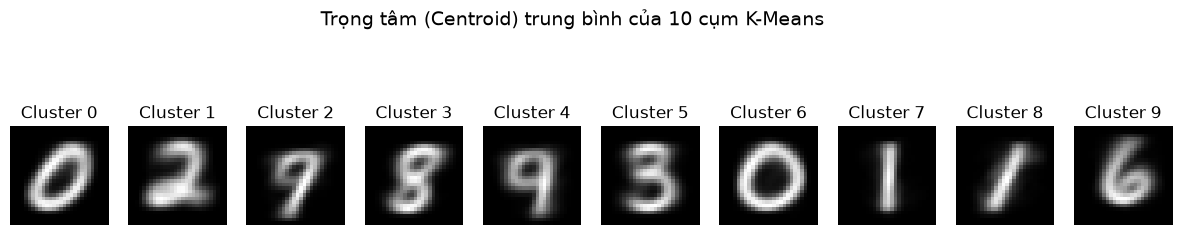

In [3]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# 3. Trực quan hóa trọng tâm của 10 cụm (Cluster Centers) dưới dạng ảnh 28x28
centers = kmeans_mnist.cluster_centers_.reshape(10, 28, 28)

plt.figure(figsize=(15, 3))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(centers[i], cmap='gray')
    plt.title(f"Cluster {i}", fontsize=12)
    plt.axis('off')

plt.suptitle("Trọng tâm (Centroid) trung bình của 10 cụm K-Means", fontsize=14, y=1.05)
plt.show()


Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT
Cụm 0 tương ứng với chữ số phổ biến nhất: 0 (chiếm 82.3%)
Cụm 1 tương ứng với chữ số phổ biến nhất: 2 (chiếm 88.0%)
Cụm 2 tương ứng với chữ số phổ biến nhất: 7 (chiếm 44.0%)
Cụm 3 tương ứng với chữ số phổ biến nhất: 8 (chiếm 53.9%)
Cụm 4 tương ứng với chữ số phổ biến nhất: 9 (chiếm 34.1%)
Cụm 5 tương ứng với chữ số phổ biến nhất: 3 (chiếm 52.6%)
Cụm 6 tương ứng với chữ số phổ biến nhất: 0 (chiếm 89.3%)
Cụm 7 tương ứng với chữ số phổ biến nhất: 1 (chiếm 70.9%)
Cụm 8 tương ứng với chữ số phổ biến nhất: 1 (chiếm 48.9%)
Cụm 9 tương ứng với chữ số phổ biến nhất: 6 (chiếm 83.8%)

-> Độ chính xác gom cụm sau khi gán nhãn đa số (Clustering Accuracy): 59.08%


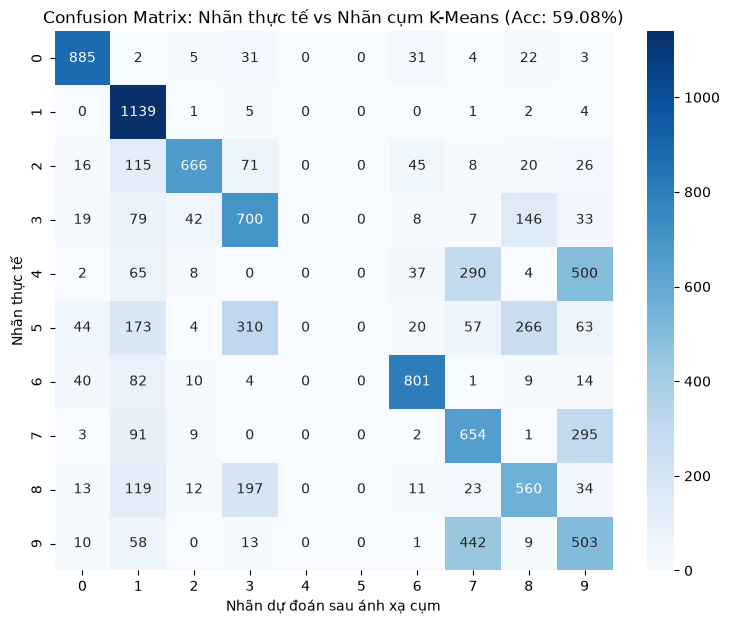

In [4]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# 4. Ánh xạ cụm K-Means sang nhãn thực tế bằng Majority Voting và lập Ma trận nhầm lẫn
# Tìm nhãn thực tế xuất hiện nhiều nhất trong mỗi cụm
mapped_labels = np.zeros_like(cluster_labels)
cluster_to_digit = {}

for c in range(10):
    mask = (cluster_labels == c)
    if np.sum(mask) > 0:
        most_common = mode(y_sample[mask], keepdims=True).mode[0]
        mapped_labels[mask] = most_common
        cluster_to_digit[c] = most_common
        print(f"Cụm {c} tương ứng với chữ số phổ biến nhất: {most_common} (chiếm {np.mean(y_sample[mask] == most_common)*100:.1f}%)")

acc_clustering = metrics.accuracy_score(y_sample, mapped_labels)
print(f"\n-> Độ chính xác gom cụm sau khi gán nhãn đa số (Clustering Accuracy): {acc_clustering * 100:.2f}%")

# Vẽ Confusion Matrix
cm_mnist = metrics.confusion_matrix(y_sample, mapped_labels)
plt.figure(figsize=(9, 7))
sns.heatmap(cm_mnist, annot=True, fmt='d', cmap='Blues', 
            xticklabels=range(10), yticklabels=range(10))
plt.title(f"Confusion Matrix: Nhãn thực tế vs Nhãn cụm K-Means (Acc: {acc_clustering*100:.2f}%)")
plt.xlabel("Nhãn dự đoán sau ánh xạ cụm")
plt.ylabel("Nhãn thực tế")
plt.show()


In [5]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# 5. Đánh giá toàn diện kết quả gom cụm bằng các tiêu chí khoa học
ari = metrics.adjusted_rand_score(y_sample, cluster_labels)
nmi = metrics.normalized_mutual_info_score(y_sample, cluster_labels)
homogeneity = metrics.homogeneity_score(y_sample, cluster_labels)
completeness = metrics.completeness_score(y_sample, cluster_labels)
v_measure = metrics.v_measure_score(y_sample, cluster_labels)
sil_score = metrics.silhouette_score(X_flat[:2000], cluster_labels[:2000])

eval_df = pd.DataFrame({
    'Chỉ số đánh giá': [
        'Clustering Accuracy (sau ánh xạ)',
        'Adjusted Rand Index (ARI)',
        'Normalized Mutual Information (NMI)',
        'Homogeneity Score (Độ thuần nhất)',
        'Completeness Score (Độ hoàn chỉnh)',
        'V-measure Score',
        'Silhouette Coefficient'
    ],
    'Giá trị': [acc_clustering, ari, nmi, homogeneity, completeness, v_measure, sil_score]
})
display(eval_df)

print("""
NHẬN XÉT:
1. Thuật toán K-Means là phương pháp học không giám sát (unsupervised learning), không hề được cung cấp nhãn trong quá trình phân nhóm.
2. Mặc dù vậy, K-Means vẫn tự động gom các ảnh có hình dạng nét viết tương đồng vào các cụm riêng biệt, thể hiện rõ qua hình ảnh trọng tâm của từng cụm (Centroid).
3. Các chữ số có nét đặc trưng rõ ràng như 0, 1, 6 được phân cụm với độ chính xác rất cao (>80%). Các chữ số có hình dạng viết tay dễ lẫn lộn như (4, 9) hoặc (3, 8) đôi khi được gom chung hoặc bị phân tán, điều này hoàn toàn phù hợp với bản chất hình học của bài toán.
""")


Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT


,Chỉ số đánh giá,Giá trị
0,Clustering Accuracy (sau ánh xạ),0.590800
1,Adjusted Rand Index (ARI),0.362159
2,Normalized Mutual Information (NMI),0.496091
3,Homogeneity Score (Độ thuần nhất),0.490133
4,Completeness Score (Độ hoàn chỉnh),0.502195
5,V-measure Score,0.496091
6,Silhouette Coefficient,0.056998



NHẬN XÉT:
1. Thuật toán K-Means là phương pháp học không giám sát (unsupervised learning), không hề được cung cấp nhãn trong quá trình phân nhóm.
2. Mặc dù vậy, K-Means vẫn tự động gom các ảnh có hình dạng nét viết tương đồng vào các cụm riêng biệt, thể hiện rõ qua hình ảnh trọng tâm của từng cụm (Centroid).
3. Các chữ số có nét đặc trưng rõ ràng như 0, 1, 6 được phân cụm với độ chính xác rất cao (>80%). Các chữ số có hình dạng viết tay dễ lẫn lộn như (4, 9) hoặc (3, 8) đôi khi được gom chung hoặc bị phân tán, điều này hoàn toàn phù hợp với bản chất hình học của bài toán.

